# Vienna imagery with STAC and S3

Publish three Sentinel-2 image crops and their STAC items in one workspace. Read the images through public STAC links and authenticated S3 clients, and check that both routes return the uploaded bytes.

First create a workspace with [Workspace Management](../workspace-management.ipynb). Use its printed name below. Files uploaded under `public/` are publicly readable.

Upload a STAC-compatible `catalog.parquet` into `public/` to make a dynamic STAC catalogue API available automatically at `/api/public/catalog/public`. Connect STAC Browser to that URL. PackageR serves the Collection and Items; it does not provide a `/search` endpoint.

Files in `public/` also get permanent PackageR HTTP download links. Each request redirects to a fresh presigned URL on the backing object storage, where the download takes place.


## Data flow

![Data flow from Sentinel-2 imagery through workspace storage to public downloads and authenticated S3 clients](../img/vienna-imagery-with-stac-and-s3/data-flow.svg)

Crop the three scenes and upload the images, previews, and catalogue through the backing S3 service. PackageR supplies public catalogue links and image downloads. Python S3 clients and the AWS CLI read the same files through the Data endpoint with the owner's token. The notebook compares downloaded files with their local SHA-256 checksums.


## 1. Prepare the runtime

From the repository root:

```bash
uv sync
uv run jupyter lab docs/getting-started/vienna-imagery-with-stac-and-s3.ipynb
```

The notebook uses `eoepca-demo.env` for service settings. Sign in as the test workspace owner with device login when prompted. Storage keys and tokens stay in kernel memory.

Install the [AWS CLI](https://docs.aws.amazon.com/cli/latest/userguide/getting-started-install.html) for step 6 if your runtime does not already provide it.


In [17]:
from __future__ import annotations

import hashlib
import json
import sys
import tempfile
from pathlib import Path
from urllib.parse import quote, urljoin

import boto3
import pystac
import rasterio
import requests
import stac_geoparquet.arrow
from botocore.config import Config
from botocore.exceptions import ClientError
from IPython.display import HTML, Image, display
from PIL import Image as PillowImage
from html import escape
from pystac.extensions.eo import EOExtension
from pystac.extensions.projection import ProjectionExtension
from rasterio.enums import Resampling
from rasterio.shutil import copy as copy_raster
from rasterio.warp import transform_bounds
from rasterio.windows import Window, from_bounds, transform as window_transform

def show_json(value):
    print(json.dumps(value, indent=2))


S3_REGION = "us-east-1"
DATASET = "vienna-s2l2a-26"
CATALOG_KEY = "public/catalog.parquet"
VIENNA_BBOX = (16.18, 48.11, 16.58, 48.32)
SOURCE_API = "https://earth-search.aws.element84.com/v1"
SOURCE_COLLECTION = "sentinel-2-c1-l2a"
SCENE_IDS = [
    "S2B_T33UXP_20260218T100524_L2A",
    "S2B_T33UXP_20260519T100022_L2A",
    "S2B_T33UWP_20260814T095452_L2A",
]

REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "docs/notebook_support.py").is_file()
)
sys.path.insert(0, str(REPO_ROOT / "docs"))
from notebook_support import (
    ApiSession, load_config, login_workspace_as, refresh_login, workspace_data_url,
)

config = load_config("eoepca-demo.env", "workspace")
WORKSPACE = input("Workspace name from Workspace Management: ").strip()
if not WORKSPACE:
    raise ValueError("Enter the test workspace name.")
BUCKET = WORKSPACE
DATA_URL = workspace_data_url(config["WORKSPACE_DATA_DOMAIN"], WORKSPACE)
WORK_DIR = Path(tempfile.mkdtemp(prefix="xyz-"))
PUBLIC_DIR = WORK_DIR / "public"
PUBLIC_DIR.mkdir()
DOWNLOAD_DIR = WORK_DIR / "downloads"
DOWNLOAD_DIR.mkdir()

# Optional: reuse the materialized PackageR fixture instead of reading source COGs.
# Set this to the directory that contains the scene directories in that checkout.
FIXTURE_DIR = None

S3_CONFIG = Config(
    signature_version="s3v4",
    s3={"addressing_style": "path"},
    connect_timeout=10,
    read_timeout=120,
    retries={"max_attempts": 3},
)
show_json({"workspace": WORKSPACE, "bucket": BUCKET, "local_directory": str(WORK_DIR)})


{
  "workspace": "ws-test-20261028071349",
  "bucket": "ws-test-20261028071349",
  "local_directory": "/tmp/xyz-n5g7_1vg"
}


## 2. Select the scenes

Use three fixed scene IDs from February, May, and August. The reported cloud cover applies to each source tile. It can differ from the cloud cover over Vienna.

Crop each image to the Vienna bounding box and write a Cloud Optimized GeoTIFF with a PNG preview. Keep the cropped grid in the STAC metadata. The August scene uses a different tile, so its available crop differs.


In [18]:
response = requests.get(f"{SOURCE_API}/collections/{SOURCE_COLLECTION}", timeout=60)
response.raise_for_status()
source_collection = response.json()
source_license_links = [link for link in source_collection["links"] if link["rel"] == "license"]

source_items = []
for scene_id in SCENE_IDS:
    source_url = f"{SOURCE_API}/collections/{SOURCE_COLLECTION}/items/{scene_id}"
    response = requests.get(source_url, timeout=60)
    response.raise_for_status()
    item = pystac.Item.from_dict(response.json(), migrate=False)
    assert item.id == scene_id
    assert "visual" in item.assets
    source_items.append((item, source_url))

show_json([
    {"id": item.id, "datetime": item.datetime.isoformat(),
     "cloud_cover": item.properties.get("eo:cloud_cover")}
    for item, _ in source_items
])

[
  {
    "id": "S2B_T33UXP_20260218T100524_L2A",
    "datetime": "2026-02-18T10:07:11.476000+00:00",
    "cloud_cover": 65.89672
  },
  {
    "id": "S2B_T33UXP_20260519T100022_L2A",
    "datetime": "2026-05-19T10:07:11.493000+00:00",
    "cloud_cover": 11.111718
  },
  {
    "id": "S2B_T33UWP_20260814T095452_L2A",
    "datetime": "2026-08-14T09:57:19.897000+00:00",
    "cloud_cover": 0.001907
  }
]


{
  "id": "S2B_T33UXP_20260218T100524_L2A",
  "bbox": [
    16.34339055064835,
    48.10529168459065,
    16.586359695887285,
    48.32299359792704
  ],
  "image_bytes": 11563761
}


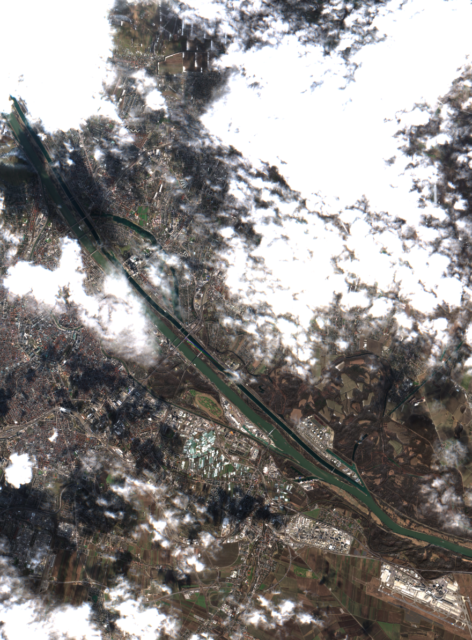

{
  "id": "S2B_T33UXP_20260519T100022_L2A",
  "bbox": [
    16.34339055064835,
    48.10529168459065,
    16.586359695887285,
    48.32299359792704
  ],
  "image_bytes": 14775151
}


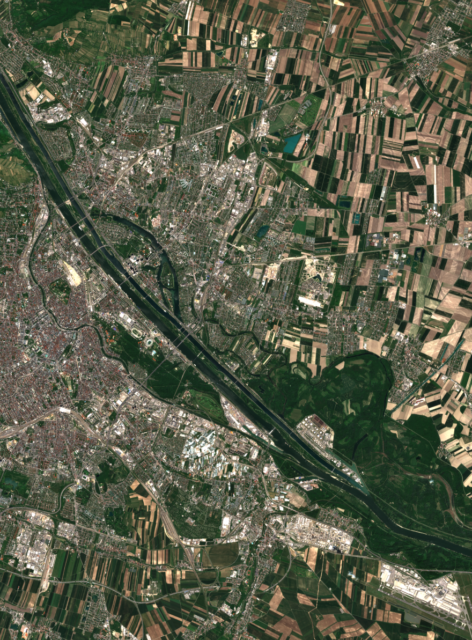

{
  "id": "S2B_T33UWP_20260814T095452_L2A",
  "bbox": [
    16.17510305462538,
    48.10668751736761,
    16.480910099625905,
    48.32485172090121
  ],
  "image_bytes": 18562434
}


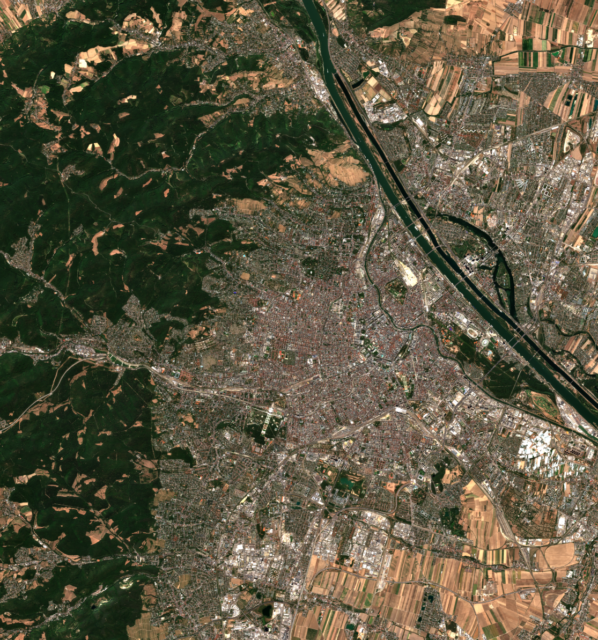

In [19]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def polygon(bounds):
    west, south, east, north = bounds
    return {
        "type": "Polygon",
        "coordinates": [[[west, south], [east, south], [east, north],
                         [west, north], [west, south]]],
    }


def prepare_image(source_item, destination):
    if FIXTURE_DIR is not None:
        source = Path(FIXTURE_DIR) / source_item.id / "overview.tif"
        if not source.is_file():
            raise FileNotFoundError(source)
        # The fixture already contains a Vienna clip. Leave the source file intact.
        copy_raster(source, destination, driver="COG", compress="DEFLATE")
        return

    temporary = destination.parent / "clipped.tif"
    try:
        with rasterio.Env(
            GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",
            CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.tiff",
        ), rasterio.open(source_item.assets["visual"].href) as source:
            bounds = transform_bounds("EPSG:4326", source.crs, *VIENNA_BBOX, densify_pts=21)
            window = from_bounds(*bounds, transform=source.transform)
            window = window.round_offsets().round_lengths().intersection(
                Window(0, 0, source.width, source.height)
            )
            pixels = source.read(window=window)
            profile = source.profile.copy()
            profile.update(
                driver="GTiff", width=pixels.shape[2], height=pixels.shape[1],
                transform=window_transform(window, source.transform),
                tiled=True, blockxsize=512, blockysize=512, compress="DEFLATE",
            )
            with rasterio.open(temporary, "w", **profile) as target:
                target.write(pixels)
                target.colorinterp = source.colorinterp
            copy_raster(temporary, destination, driver="COG", compress="DEFLATE",
                        overview_resampling="AVERAGE")
    finally:
        temporary.unlink(missing_ok=True)


items = []
for source_item, source_url in source_items:
    directory = PUBLIC_DIR / DATASET / source_item.id
    directory.mkdir(parents=True, exist_ok=True)
    image_path = directory / "overview.tif"
    preview_path = directory / "preview.png"
    prepare_image(source_item, image_path)

    with rasterio.open(image_path) as image:
        assert image.count == 3 and image.dtypes == ("uint8",) * 3
        bounds = list(transform_bounds(image.crs, "EPSG:4326", *image.bounds, densify_pts=21))
        item = pystac.Item(
            id=source_item.id, geometry=polygon(bounds), bbox=bounds,
            datetime=source_item.datetime,
            properties={"title": "Vienna colour image", "license": source_collection["license"]},
        )
        for link in source_license_links:
            item.add_link(pystac.Link.from_dict(link))
        projection = {
            "code": f"EPSG:{image.crs.to_epsg()}",
            "shape": [image.height, image.width],
            "transform": list(image.transform)[:6],
        }
        cloud_cover = source_item.properties.get("eo:cloud_cover")
        if cloud_cover is not None:
            EOExtension.ext(item, add_if_missing=True).apply(cloud_cover=cloud_cover)
        item.add_link(pystac.Link(rel="derived_from", target=source_url,
                                 media_type="application/geo+json"))
        scale = min(1, 640 / max(image.width, image.height))
        preview = image.read(
            out_shape=(3, max(1, round(image.height * scale)), max(1, round(image.width * scale))),
            resampling=Resampling.bilinear,
        )

    # A display preview has no geographic grid. Write it as an ordinary PNG.
    PillowImage.fromarray(preview.transpose(1, 2, 0)).save(preview_path)
    item.add_asset("overview", pystac.Asset(
        href=image_path.relative_to(PUBLIC_DIR).as_posix(),
        media_type="image/tiff; application=geotiff; profile=cloud-optimized",
        title="Vienna colour COG", roles=["visual"],
    ))
    ProjectionExtension.ext(item.assets["overview"], add_if_missing=True).apply(**projection)
    item.add_asset("preview", pystac.Asset(
        href=preview_path.relative_to(PUBLIC_DIR).as_posix(),
        media_type="image/png", title="Vienna preview", roles=["thumbnail"],
    ))
    items.append(item)
    show_json({"id": item.id, "bbox": item.bbox, "image_bytes": image_path.stat().st_size})
    display(Image(filename=str(preview_path)))

## 3. Write the STAC catalogue

The public share reads `public/catalog.parquet`. Asset paths must be relative to `public`, such as `vienna-s2l2a-26/<scene-id>/overview.tif`. PackageR turns those paths into public download links in returned STAC Items.

The catalogue records the source scene links, license, and cropped grid. It contains colour imagery and previews; use the original reflectance bands for numerical analysis.


In [20]:
catalog_path = PUBLIC_DIR / "catalog.parquet"
table = stac_geoparquet.arrow.parse_stac_items_to_arrow([item.to_dict() for item in items]).read_all()
stac_geoparquet.arrow.to_parquet(table, catalog_path)

# Include only the catalog and the assets named in its Items.
publish_files = {CATALOG_KEY: catalog_path}
for item in items:
    for asset in item.assets.values():
        publish_files[f"public/{asset.href}"] = PUBLIC_DIR / asset.href
expected_hashes = {key: sha256(path) for key, path in publish_files.items()}
show_json({"catalog_rows": table.num_rows, "files": len(publish_files),
       "total_bytes": sum(path.stat().st_size for path in publish_files.values())})

{
  "catalog_rows": 3,
  "files": 7,
  "total_bytes": 46944180
}


## 4. Upload via backing S3

Sign in as the workspace owner. If this kernel already has that owner's login, refresh it; otherwise, complete device login. The Workspace API supplies its backing storage credentials. The Data S3 endpoint used later is read only.

Check existing files by SHA-256. Skip matching files and stop if a key has different content. Upload the catalogue after its assets.


In [22]:
api = ApiSession()
import jwt

OWNER = "alice"  # Change to your workspace owner.
# Reuse an owner login when the notebooks run in the same kernel.
previous_tokens = globals().get("owner_tokens")
owner_tokens = None
if previous_tokens:
    claims = jwt.decode(previous_tokens["access_token"], options={"verify_signature": False})
    if claims.get("preferred_username") == OWNER:
        try:
            owner_tokens = refresh_login(config, "workspace", previous_tokens)
            print(f"Refreshed the existing {OWNER} login.")
        except (ValueError, RuntimeError):
            pass
if not owner_tokens:
    owner_tokens = login_workspace_as(config, OWNER)
response = api.get(
    f"{config['WORKSPACE_API_ENDPOINT']}/{WORKSPACE}",
    headers={"Authorization": f"Bearer {owner_tokens['access_token']}"},
)
response.raise_for_status()
workspace_data = response.json()
credentials = workspace_data["storage"].get("credentials")
if not credentials or credentials["bucketname"] != BUCKET:
    raise PermissionError("The owner must have storage access to this workspace.")
storage = boto3.client(
    "s3", endpoint_url=credentials["endpoint"],
    aws_access_key_id=credentials["access"],
    aws_secret_access_key=credentials["secret"],
    region_name=credentials["region"], config=S3_CONFIG,
)


def object_sha256(client, key):
    response = client.get_object(Bucket=BUCKET, Key=key)
    digest = hashlib.sha256()
    with response["Body"] as body:
        for chunk in iter(lambda: body.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


existing = set()
for key in publish_files:
    try:
        storage.head_object(Bucket=BUCKET, Key=key)
    except ClientError as error:
        if error.response["Error"]["Code"] not in ("404", "NoSuchKey", "NotFound"):
            raise
    else:
        if object_sha256(storage, key) != expected_hashes[key]:
            raise RuntimeError(f"Existing object has different content: s3://{BUCKET}/{key}")
        existing.add(key)

for key in sorted(publish_files, key=lambda key: key == CATALOG_KEY):
    if key in existing:
        continue
    path = publish_files[key]
    media_type = (
        "application/vnd.apache.parquet" if path.suffix == ".parquet" else
        "image/png" if path.suffix == ".png" else
        "image/tiff; application=geotiff; profile=cloud-optimized"
    )
    with path.open("rb") as body:
        storage.put_object(
            Bucket=BUCKET, Key=key, Body=body, ContentType=media_type,
            Metadata={"sha256": expected_hashes[key]}, IfNoneMatch="*",
        )
    assert object_sha256(storage, key) == expected_hashes[key]

show_json({"route": "upload via backing S3", "uploaded": len(publish_files) - len(existing), "already_present": len(existing),
       "public_share": f"{DATA_URL}/share/public/"})

Refreshed the existing alice login.


{
  "route": "upload via backing S3",
  "uploaded": 7,
  "already_present": 0,
  "public_share": "https://ws-test-20261028071349.lab.develop-v2.eoepca.org/share/public/"
}


## 5. Browse STAC and download via the PackageR HTTP API

The public share reads `public/catalog.parquet`. Follow its Item links to the images. This catalogue has no `/search` endpoint.

The cells check the three STAC items, download a COG and preview, and compare their checksums with the local files.


In [23]:
from notebook_support import wait_for_data
wait_for_data(requests.Session(), DATA_URL)

catalog_url = f"{DATA_URL}/api/public/catalog/public"
response = requests.get(catalog_url, timeout=120)
response.raise_for_status()
collection = response.json()
assert collection["type"] == "Collection" and collection["id"] == "public"
item_links = [link for link in collection["links"] if link["rel"] == "item"]
served_items = []
for link in item_links:
    response = requests.get(urljoin(catalog_url, link["href"]), timeout=120)
    response.raise_for_status()
    item = response.json()
    assert item["type"] == "Feature" and item["geometry"] and item["bbox"]
    for asset in item["assets"].values():
        assert asset["href"].startswith(f"{DATA_URL}/api/public/share/public/")
    served_items.append(item)
assert {item["id"] for item in served_items} == set(SCENE_IDS)
served_item = next(item for item in served_items if item["id"] == SCENE_IDS[0])

show_json({"collection": collection["id"], "extent": collection["extent"],
       "items": [item["id"] for item in served_items],
       "first_item": next(link["href"] for link in served_item["links"] if link["rel"] == "self")})

Waiting for the Data endpoint...


Data endpoint ready.


{
  "collection": "public",
  "extent": {
    "spatial": {
      "bbox": [
        [
          16.17510305462538,
          48.10529168459065,
          16.586359695887285,
          48.32485172090121
        ]
      ]
    },
    "temporal": {
      "interval": [
        [
          "2026-02-18T10:07:11.476Z",
          "2026-08-14T09:57:19.897Z"
        ]
      ]
    }
  },
  "items": [
    "S2B_T33UXP_20260218T100524_L2A",
    "S2B_T33UXP_20260519T100022_L2A",
    "S2B_T33UWP_20260814T095452_L2A"
  ],
  "first_item": "https://ws-test-20261028071349.lab.develop-v2.eoepca.org/api/public/catalog/public/vienna-s2l2a-26/S2B_T33UXP_20260218T100524_L2A/"
}


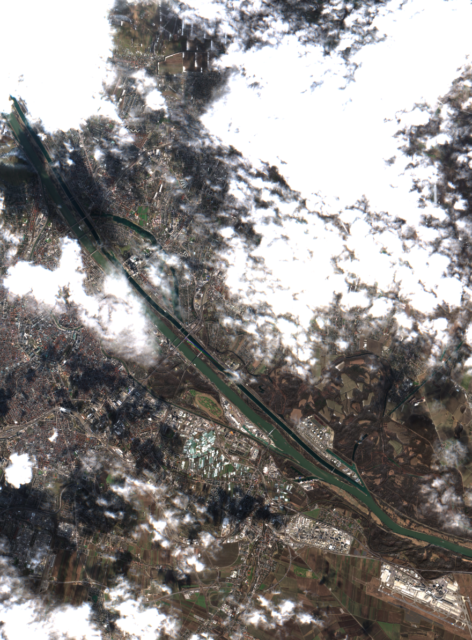

{
  "route": "download via the PackageR HTTP API",
  "download": "/tmp/xyz-n5g7_1vg/downloads/public-overview.tif",
  "sha256_matches": true
}


In [24]:
def download_public(url, destination):
    # The asset URL redirects to a short-lived backing storage URL.
    # Keep that signed URL out of output and files.
    with requests.get(url, stream=True, timeout=(10, 120)) as response:
        if response.status_code != 200:
            raise RuntimeError(f"Public download failed (HTTP {response.status_code}).")
        with destination.open("wb") as output:
            for chunk in response.iter_content(1024 * 1024):
                output.write(chunk)


first_image_key = f"public/{DATASET}/{served_item['id']}/overview.tif"
public_download = DOWNLOAD_DIR / "public-overview.tif"
download_public(served_item["assets"]["overview"]["href"], public_download)
assert sha256(public_download) == expected_hashes[first_image_key]
public_preview = DOWNLOAD_DIR / "public-preview.png"
download_public(served_item["assets"]["preview"]["href"], public_preview)
assert sha256(public_preview) == expected_hashes[f"public/{DATASET}/{served_item['id']}/preview.png"]
display(Image(filename=str(public_preview)))
show_json({"route": "download via the PackageR HTTP API", "download": str(public_download), "sha256_matches": True})

Share the permanent asset links returned by the PackageR HTTP API. Their redirects lead to storage URLs that expire. To get the presigned URL as JSON, call `GET <Data URL>/api/public/share/public/<asset-path>?presign=true` and read `presignedURL`. Add `&followRedirect=true` to redirect to the object-storage download instead.


### Browse the PackageR catalogue

PackageR builds a catalogue from the uploaded STAC GeoParquet file at `/api/public/catalog/public`. It serves a Collection and its Items through the existing Data service. This catalogue has no `/search` route. See the [notebook guide](../usage/notebook-guide.md#process-data-and-add-search) for the two STAC search APIs.

Open it in STAC Browser to view the three scenes on a map and browse their image assets.


In [25]:
browser_url = f"https://browser.moregeo.it/external/{catalog_url.removeprefix('https://')}"
display(HTML(
    f'<p><a href="{escape(catalog_url, quote=True)}" target="_blank" rel="noopener">Open the STAC catalogue API</a>'
    f' · <a href="{escape(browser_url, quote=True)}" target="_blank" rel="noopener">Open STAC Browser</a></p>'
))


## 6. Read and download via S3 with Keycloak device login

Use Keycloak device login for read-only access through the Data S3 endpoint. No backing bucket credentials are used here. The workspace name supplies the two S3 signing fields; the Keycloak access token in the session-token field grants access. This endpoint supports S3 reads, not writes.

This approach is being proposed for wider STAC authentication use in [authentication extension PR 48](https://github.com/stac-extensions/authentication/pull/48); it is not a workspace-only convention or an adopted standard.

The token needs the workspace audience and access role. If login has expired, repeat step 4.


In [26]:
# Refresh the Keycloak login and use its token for read-only S3 access.
owner_tokens = refresh_login(config, "workspace", owner_tokens)
gateway = boto3.client(
    "s3", endpoint_url=DATA_URL, region_name=S3_REGION, config=S3_CONFIG,
    aws_access_key_id=WORKSPACE,
    aws_secret_access_key=WORKSPACE,
    aws_session_token=owner_tokens["access_token"],
)
show_json({"endpoint": DATA_URL, "login": "Keycloak device flow", "access": "read only; no backing bucket credentials"})


{
  "endpoint": "https://ws-test-20261028071349.lab.develop-v2.eoepca.org",
  "login": "Keycloak device flow",
  "access": "read only; no backing bucket credentials"
}


In [27]:
# List via S3, inspect an object, and verify a byte-range read.
buckets = gateway.list_buckets()["Buckets"]
assert BUCKET in {bucket["Name"] for bucket in buckets}
listed = []
for page in gateway.get_paginator("list_objects_v2").paginate(
    Bucket=BUCKET, Prefix=f"public/{DATASET}/"
):
    listed.extend(page.get("Contents", []))
assert set(publish_files) - {CATALOG_KEY} <= {entry["Key"] for entry in listed}
show_json({"buckets": [bucket["Name"] for bucket in buckets],
       "objects": [{"key": entry["Key"], "bytes": entry["Size"]} for entry in listed]})

head = gateway.head_object(Bucket=BUCKET, Key=first_image_key)
assert head["ContentLength"] == publish_files[first_image_key].stat().st_size
response = gateway.get_object(Bucket=BUCKET, Key=first_image_key, Range="bytes=0-1023")
with response["Body"] as body:
    first_bytes = body.read()
assert response["ResponseMetadata"]["HTTPStatusCode"] in (200, 206)
assert response["ContentRange"] == f"bytes 0-1023/{head['ContentLength']}"
with publish_files[first_image_key].open("rb") as source:
    assert first_bytes == source.read(1024)
show_json({"head_bytes": head["ContentLength"], "range_bytes": len(first_bytes),
       "range_matches": True})

{
  "buckets": [
    "ws-test-20261028071349"
  ],
  "objects": [
    {
      "key": "public/vienna-s2l2a-26/S2B_T33UXP_20260218T100524_L2A/overview.tif",
      "bytes": 11563761
    },
    {
      "key": "public/vienna-s2l2a-26/S2B_T33UXP_20260218T100524_L2A/preview.png",
      "bytes": 526733
    },
    {
      "key": "public/vienna-s2l2a-26/S2B_T33UXP_20260519T100022_L2A/overview.tif",
      "bytes": 14775151
    },
    {
      "key": "public/vienna-s2l2a-26/S2B_T33UXP_20260519T100022_L2A/preview.png",
      "bytes": 663900
    },
    {
      "key": "public/vienna-s2l2a-26/S2B_T33UWP_20260814T095452_L2A/overview.tif",
      "bytes": 18562434
    },
    {
      "key": "public/vienna-s2l2a-26/S2B_T33UWP_20260814T095452_L2A/preview.png",
      "bytes": 834082
    }
  ]
}
{
  "head_bytes": 11563761,
  "range_bytes": 1024,
  "range_matches": true
}


In [28]:
# Download via S3 and compare all seven files with their local checksums.
for key in publish_files:
    destination = DOWNLOAD_DIR / "s3" / key.removeprefix("public/")
    destination.parent.mkdir(parents=True, exist_ok=True)
    response = gateway.get_object(Bucket=BUCKET, Key=key)
    with response["Body"] as body, destination.open("wb") as output:
        for chunk in iter(lambda: body.read(1024 * 1024), b""):
            output.write(chunk)
    assert sha256(destination) == expected_hashes[key]
show_json({"verified_s3_downloads": len(publish_files),
       "directory": str(DOWNLOAD_DIR / "s3"), "sha256_matches": True})

{
  "verified_s3_downloads": 7,
  "directory": "/tmp/xyz-n5g7_1vg/downloads/s3",
  "sha256_matches": true
}


In [29]:
# Use the same Keycloak login with the AWS CLI to list and download via S3.
from notebook_support import aws_cli

owner_tokens = refresh_login(config, "workspace", owner_tokens)
cli_download = DOWNLOAD_DIR / "cli-overview.tif"
with aws_cli(DATA_URL, WORKSPACE, owner_tokens["access_token"], S3_REGION) as aws:
    aws("s3", "ls", f"s3://{BUCKET}/public/{DATASET}/")
    aws("s3", "cp", f"s3://{BUCKET}/{first_image_key}", str(cli_download), "--no-progress")

assert sha256(cli_download) == expected_hashes[first_image_key]
show_json({"cli_download_sha256_matches": True})


PRE S2B_T33UWP_20260814T095452_L2A/
                           PRE S2B_T33UXP_20260218T100524_L2A/
                           PRE S2B_T33UXP_20260519T100022_L2A/


download: s3://ws-test-20261028071349/public/vienna-s2l2a-26/S2B_T33UXP_20260218T100524_L2A/overview.tif to ../../../../../../tmp/xyz-n5g7_1vg/downloads/cli-overview.tif
{
  "cli_download_sha256_matches": true
}


## Result

The workspace holds three COG images, three PNG previews, and one catalogue. The public image and preview downloads, all seven S3 downloads, and the CLI image download match the local SHA-256 checksums. A byte-range request returns the requested part of an image.
